<a href="https://colab.research.google.com/github/Anet-Bino/Predictive_Analytics_Project/blob/main/Predictive_Analytics_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
data = {
    'Month': pd.date_range(start='2022-01-01', periods=48, freq='MS'),
    'Sales': [
        12000, 13500, 12800, 14500, 15000, 16000,
        15500, 17000, 18000, 17500, 19000, 20000,
        19500, 21000, 20500, 22000, 23000, 22500,
        24000, 25000, 24500, 26000, 27000, 28000,
        27500, 29000, 30000, 29500, 31000, 32000,
        31500, 33000, 34000, 33500, 35000, 36000,
        35500, 37000, 38000, 37500, 39000, 40000,
        39500, 41000, 42000, 41500, 43000, 44000
    ]
}

df = pd.DataFrame(data)

df.head()

,Month,Sales
0,2022-01-01,12000
1,2022-02-01,13500
2,2022-03-01,12800
3,2022-04-01,14500
4,2022-05-01,15000


In [3]:
# Display the dataset
print("Dataset Shape:", df.shape)

# Display all records
display(df)

Dataset Shape: (48, 2)


,Month,Sales
0,2022-01-01,12000
1,2022-02-01,13500
2,2022-03-01,12800
3,2022-04-01,14500
4,2022-05-01,15000
5,2022-06-01,16000
6,2022-07-01,15500
7,2022-08-01,17000
8,2022-09-01,18000
9,2022-10-01,17500


In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
Month    0
Sales    0
dtype: int64

Duplicate Records:
0


In [5]:
# Convert Month into datetime format
df['Month'] = pd.to_datetime(df['Month'])

# Create a numerical time column
df['Month_Number'] = np.arange(1, len(df) + 1)

# Display updated dataset
display(df.head())

,Month,Sales,Month_Number
0,2022-01-01,12000,1
1,2022-02-01,13500,2
2,2022-03-01,12800,3
3,2022-04-01,14500,4
4,2022-05-01,15000,5


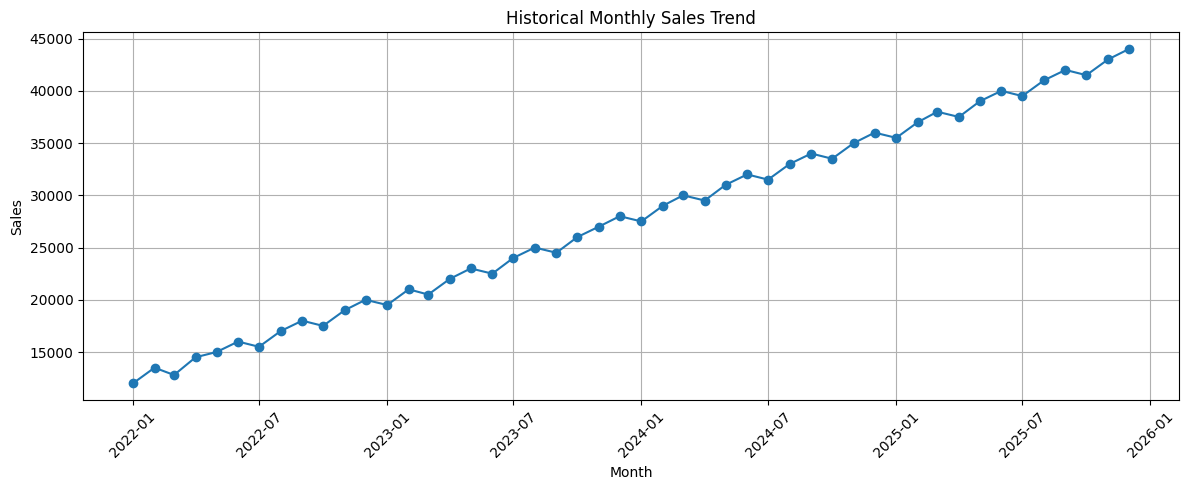

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(df['Month'], df['Sales'], marker='o')

plt.title('Historical Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()

In [7]:
# Define input and output
X = df[['Month_Number']]
y = df['Sales']

# Split data (80% training, 20% testing)
split_index = int(len(df) * 0.8)

X_train = X[:split_index]
X_test = X[split_index:]

y_train = y[:split_index]
y_test = y[split_index:]

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 38
Testing data: 10


In [8]:
# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [9]:
# Predict sales using test data
y_pred = model.predict(X_test)

# Display actual vs predicted sales
results = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred
})

display(results)

,Actual Sales,Predicted Sales
0,38000,37419.203414
1,37500,38085.370391
2,39000,38751.537367
3,40000,39417.704344
4,39500,40083.871321
5,41000,40750.038297
6,42000,41416.205274
7,41500,42082.372251
8,43000,42748.539227
9,44000,43414.706204


In [10]:
# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Model Evaluation Results
------------------------
Mean Absolute Error: 483.37
Mean Squared Error: 256994.67
Root Mean Squared Error: 506.95
R2 Score: 0.9369


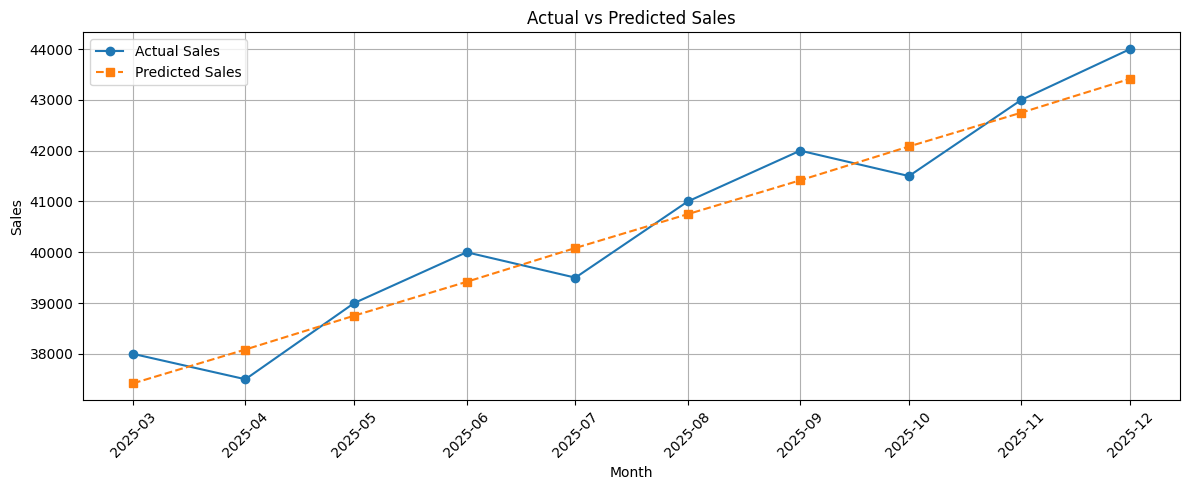

In [11]:
plt.figure(figsize=(12, 5))

plt.plot(df['Month'].iloc[38:], y_test,
         marker='o', label='Actual Sales')

plt.plot(df['Month'].iloc[38:], y_pred,
         marker='s', linestyle='--', label='Predicted Sales')

plt.title('Actual vs Predicted Sales')
plt.xlabel('Month')
plt.ylabel('Sales')

plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [12]:
# Generate future month numbers
future_months = np.arange(49, 55).reshape(-1, 1)

# Predict future sales
future_sales = model.predict(future_months)

# Create future dates
future_dates = pd.date_range(
    start='2026-01-01',
    periods=6,
    freq='MS'
)

# Create forecast table
forecast = pd.DataFrame({
    'Month': future_dates,
    'Predicted Sales': future_sales
})

display(forecast.round(2))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


,Month,Predicted Sales
0,2026-01-01,44080.87
1,2026-02-01,44747.04
2,2026-03-01,45413.21
3,2026-04-01,46079.37
4,2026-05-01,46745.54
5,2026-06-01,47411.71


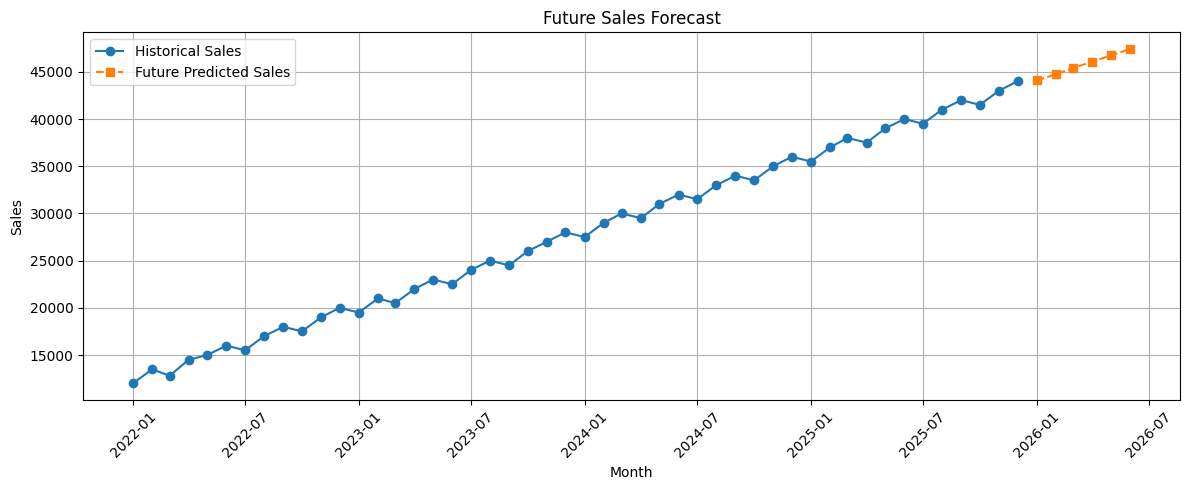

In [13]:
plt.figure(figsize=(12, 5))

plt.plot(df['Month'], df['Sales'],
         label='Historical Sales', marker='o')

plt.plot(forecast['Month'], forecast['Predicted Sales'],
         label='Future Predicted Sales',
         marker='s', linestyle='--')

plt.title('Future Sales Forecast')
plt.xlabel('Month')
plt.ylabel('Sales')

plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [14]:
print("================================")
print(" PREDICTIVE ANALYTICS PROJECT")
print("================================")

print("\nProject: Historical Sales Forecasting")

print("\nDataset Information:")
print("Total Records:", len(df))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nModel Used:")
print("Linear Regression")

print("\nModel Performance:")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

print("\nFuture Sales Predictions:")
display(forecast.round(2))

print("\nProject Completed Successfully!")

 PREDICTIVE ANALYTICS PROJECT

Project: Historical Sales Forecasting

Dataset Information:
Total Records: 48
Training Records: 38
Testing Records: 10

Model Used:
Linear Regression

Model Performance:
MAE: 483.37
RMSE: 506.95
R2 Score: 0.9369

Future Sales Predictions:


,Month,Predicted Sales
0,2026-01-01,44080.87
1,2026-02-01,44747.04
2,2026-03-01,45413.21
3,2026-04-01,46079.37
4,2026-05-01,46745.54
5,2026-06-01,47411.71



Project Completed Successfully!
